<div style="background:linear-gradient(120deg,#4F46E5,#7E22CE);color:#fff;padding:26px 30px;border-radius:14px;font-family:'Segoe UI',IBM Plex Sans,sans-serif">
<div style="font-family:'Consolas',monospace;font-size:0.78rem;opacity:.85;letter-spacing:.12em">INF672 · MACHINE LEARNING · UNIDAD 3 · PRÁCTICA 2</div>
<h1 style="margin:8px 0 4px 0;font-size:1.85rem;font-weight:700">Regresión lineal múltiple</h1>
<div style="font-size:1.05rem;opacity:.95">Predecir el costo anual de un seguro médico</div>
</div>

**Estudiante:** Abdair Magdiel Coca Carlo · **Materia:** INF672 Machine Learning (UATF) · **Docente:** M. Sc. Húscar F. Gonzales G. · **Unidad 3**

> Cuaderno de la **Práctica 2** con código y respuestas. Los pasos 01–09 forman **un solo flujo**:
> cada uno usa lo que obtuviste en el anterior. Cada paso tiene su enunciado, su celda de código
> y un bloque **Respuestas** con la interpretación.

<div style="border-left:4px solid #6B7280;background:#F9FAFB;padding:12px 18px;border-radius:0 8px 8px 0;margin:8px 0;font-family:'Segoe UI',sans-serif">
<div style="color:#6B7280;font-weight:700;font-size:0.78rem;letter-spacing:.08em;text-transform:uppercase">Cómo se resuelve</div>
<div style="margin-top:6px;line-height:1.55">
En esta práctica vas a resolver un problema completo: entrenar un modelo de regresión lineal múltiple que prediga el costo anual del seguro médico de una persona a partir de sus características. A diferencia de la Práctica 1, los pasos no son ejercicios independientes: forman un solo flujo de trabajo, y cada paso usa lo que obtuviste en el anterior.
</div>
<div style="margin-top:8px;line-height:1.55">
Esta práctica es un <strong>trabajo individual</strong>. Las respuestas escritas deben apoyarse en los resultados que <strong>tú</strong> obtengas al ejecutar tu código: no basta con mostrar números, hay que <strong>interpretarlos en el contexto del problema</strong>.
</div>
</div>

<div style="border-left:4px solid #4F46E5;background:#EEF2FF;padding:12px 18px;border-radius:0 8px 8px 0;margin:8px 0;font-family:'Segoe UI',sans-serif">
<div style="color:#4F46E5;font-weight:700;font-size:0.78rem;letter-spacing:.08em;text-transform:uppercase">Entrega</div>
<div style="margin-top:6px;line-height:1.55">
Desarrolla un notebook de Jupyter que incluya tanto el código ejecutado como tus respuestas escritas en celdas de texto, organizado con un título por cada paso. Súbelo a tu repositorio de GitHub junto con el archivo de datos y envía el enlace a la plataforma virtual en el apartado de <em>Práctica 2</em>.
</div>
</div>

## El problema

### ¿Cuánto costará asegurar a esta persona?

Una compañía de seguros de salud necesita estimar, antes de firmar un contrato, cuánto le costará en gastos médicos cada nuevo asegurado durante un año. Si subestima el costo, pierde dinero; si lo sobrestima, cobra primas demasiado altas y pierde clientes. La compañía dispone del historial de **1 338 asegurados** y te pide un modelo que, con la información que se recoge en la solicitud del seguro, estime el costo médico anual.

Además de predecir bien, la compañía necesita entender el modelo: quiere saber **qué características de una persona encarecen el seguro y en qué medida**. Por eso se usará regresión lineal múltiple, un modelo cuyos coeficientes pueden interpretarse directamente en dólares.

## El dataset · archivo `insurance.csv`

El archivo `insurance.csv` (está en esta misma carpeta) contiene **1 338 filas** (una por asegurado) y **7 columnas**. Es el conjunto de datos público *Medical Cost Personal Dataset*, construido a partir de estadísticas demográficas de Estados Unidos. Seis columnas describen al asegurado y la séptima, `charges`, es la variable que el modelo debe predecir.

| Variable | Tipo | Descripción |
|---|---|---|
| `age` | Numérica | Edad del titular del seguro, en años. |
| `sex` | Categórica | Sexo del titular: `female` o `male`. |
| `bmi` | Numérica | Índice de masa corporal: peso (kg) dividido entre la estatura al cuadrado (m²). Valores de 18.5 a 24.9 se consideran peso normal y de 30 o más, obesidad. |
| `children` | Numérica discreta | Número de hijos o dependientes cubiertos por el seguro. |
| `smoker` | Categórica | Indica si la persona fuma: `yes` o `no`. |
| `region` | Categórica | Región de residencia en EE. UU.: `northeast`, `northwest`, `southeast` o `southwest`. |
| `charges` | Numérica (objetivo) | Costo médico anual facturado por el seguro, en dólares (USD). Es la variable a predecir. |

<div style="border-left:4px solid #F59E0B;background:#FFFBEB;padding:10px 16px;border-radius:0 8px 8px 0;margin:10px 0;font-family:'Segoe UI',sans-serif">
<div style="color:#B45309;font-weight:700;font-size:0.78rem;letter-spacing:.08em;text-transform:uppercase">Ojo</div>
<div style="margin-top:4px;line-height:1.5">Tres de las variables de entrada (<code>sex</code>, <code>smoker</code> y <code>region</code>) contienen texto y no números, así que no pueden entrar al modelo tal como están. El procedimiento siguiente te guía por todas las etapas: preparar los datos, entrenar el modelo, evaluarlo, interpretarlo y usarlo para predecir.</div>
</div>

<div style="display:flex;flex-wrap:wrap;gap:8px;margin:14px 0;font-family:'Segoe UI',sans-serif">
<span style="background:#EEF2FF;color:#4F46E5;border:1px solid #C7D2FE;padding:6px 12px;border-radius:999px;font-size:0.85rem;font-weight:600">01 · Entorno</span>
<span style="background:#EEF2FF;color:#4F46E5;border:1px solid #C7D2FE;padding:6px 12px;border-radius:999px;font-size:0.85rem;font-weight:600">02 · Cargar datos</span>
<span style="background:#EEF2FF;color:#4F46E5;border:1px solid #C7D2FE;padding:6px 12px;border-radius:999px;font-size:0.85rem;font-weight:600">03 · Codificar</span>
<span style="background:#EEF2FF;color:#4F46E5;border:1px solid #C7D2FE;padding:6px 12px;border-radius:999px;font-size:0.85rem;font-weight:600">04 · Dividir</span>
<span style="background:#EEF2FF;color:#4F46E5;border:1px solid #C7D2FE;padding:6px 12px;border-radius:999px;font-size:0.85rem;font-weight:600">05 · Entrenar</span>
<span style="background:#EEF2FF;color:#4F46E5;border:1px solid #C7D2FE;padding:6px 12px;border-radius:999px;font-size:0.85rem;font-weight:600">06 · Evaluar</span>
<span style="background:#EEF2FF;color:#4F46E5;border:1px solid #C7D2FE;padding:6px 12px;border-radius:999px;font-size:0.85rem;font-weight:600">07 · Interpretar</span>
<span style="background:#EEF2FF;color:#4F46E5;border:1px solid #C7D2FE;padding:6px 12px;border-radius:999px;font-size:0.85rem;font-weight:600">08 · Visualizar</span>
<span style="background:#EEF2FF;color:#4F46E5;border:1px solid #C7D2FE;padding:6px 12px;border-radius:999px;font-size:0.85rem;font-weight:600">09 · Predecir</span>
</div>

<div style="background:linear-gradient(120deg,#4F46E5,#7E22CE);color:#fff;padding:14px 20px;border-radius:10px;margin-top:22px;font-family:'Segoe UI',sans-serif">
<div style="font-family:'Consolas',monospace;font-size:0.72rem;opacity:.85;letter-spacing:.12em">PASO 01</div>
<div style="font-size:1.25rem;font-weight:700">Preparar el entorno de trabajo</div>
</div>

Todo el trabajo se apoya en unas pocas librerías de Python. Antes de escribir código conviene tener claro qué papel cumple cada una.

1. Crea un notebook nuevo y coloca el archivo `insurance.csv` en la misma carpeta.
2. Importa `pandas` para manejar la tabla de datos y `matplotlib.pyplot` para graficar.
3. Desde scikit-learn importa `train_test_split` (módulo `model_selection`), `LinearRegression` (módulo `linear_model`) y las métricas `r2_score` y `mean_absolute_error` (módulo `metrics`).

<div style="border-left:4px solid #7E22CE;background:#F5F3FF;padding:12px 18px;border-radius:0 8px 8px 0;margin:12px 0;font-family:'Segoe UI',sans-serif">
<div style="color:#7E22CE;font-weight:700;font-size:0.78rem;letter-spacing:.08em;text-transform:uppercase">Para entregar · Paso 01</div>
<ul style="margin:8px 0 0 0;padding-left:18px;line-height:1.55">
<li>La celda de importaciones <strong>ejecutada sin errores</strong>.</li>
<li>Una tabla breve que indique, con tus palabras, <strong>para qué usarás cada librería o función importada</strong>.</li>
</ul>
</div>

In [ ]:
# Paso 01: importamos todo lo que vamos a usar
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

print("Librerias importadas sin errores.")

<div style="background:#059669;color:#fff;padding:8px 16px;border-radius:8px;font-family:'Segoe UI',sans-serif;font-weight:700;font-size:0.95rem;display:inline-block">Respuestas · Paso 01</div>

| Librería / función | ¿Para qué la uso en esta práctica? |
|---|---|
| `pandas` | Leer el archivo CSV y manejar la tabla de datos (DataFrame). |
| `matplotlib.pyplot` | Hacer el gráfico de puntos del Paso 08. |
| `train_test_split` | Dividir los datos en entrenamiento (80 %) y prueba (20 %). |
| `LinearRegression` | Crear y entrenar el modelo de regresión lineal. |
| `r2_score` | Calcular el R²: qué proporción de la variación del costo explica el modelo. |
| `mean_absolute_error` | Calcular el MAE: en cuántos dólares se equivoca el modelo en promedio. |

<div style="background:linear-gradient(120deg,#4F46E5,#7E22CE);color:#fff;padding:14px 20px;border-radius:10px;margin-top:22px;font-family:'Segoe UI',sans-serif">
<div style="font-family:'Consolas',monospace;font-size:0.72rem;opacity:.85;letter-spacing:.12em">PASO 02</div>
<div style="font-size:1.25rem;font-weight:700">Cargar y conocer los datos</div>
</div>

Antes de entrenar cualquier modelo hay que ver cómo son los datos: cuántos registros hay, qué columnas tienen y qué tipo de valores contienen.

1. Carga el archivo con `pd.read_csv` en un DataFrame llamado `df`.
2. Muestra las dimensiones de la tabla con `df.shape` y las primeras filas con `df.head()`.
3. Revisa el tipo de cada columna con `df.info()`.

<div style="border-left:4px solid #7E22CE;background:#F5F3FF;padding:12px 18px;border-radius:0 8px 8px 0;margin:12px 0;font-family:'Segoe UI',sans-serif">
<div style="color:#7E22CE;font-weight:700;font-size:0.78rem;letter-spacing:.08em;text-transform:uppercase">Para entregar · Paso 02</div>
<div style="margin-top:6px">Las salidas de las tres instrucciones. Responde:</div>
<ul style="margin:6px 0 0 0;padding-left:18px;line-height:1.55">
<li>¿Cuántos asegurados y cuántas columnas tiene el dataset?</li>
<li>¿Qué representa una fila?</li>
<li>¿Qué columnas contienen texto y cuáles contienen números?</li>
<li>¿Cuál es la variable que queremos predecir?</li>
</ul>
</div>

In [ ]:
# Paso 02a: cargar el archivo y ver su tamano
df = pd.read_csv("insurance.csv")

print("Forma (filas, columnas):", df.shape)
df.head()

Forma (filas, columnas): (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [ ]:
# Paso 02b: tipo de cada columna y valores no nulos
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


<div style="background:#059669;color:#fff;padding:8px 16px;border-radius:8px;font-family:'Segoe UI',sans-serif;font-weight:700;font-size:0.95rem;display:inline-block">Respuestas · Paso 02</div>

- **1 338 asegurados y 7 columnas**: `df.shape` devuelve `(1338, 7)`.
- **Una fila = un asegurado.** Guarda sus datos (edad, sexo, BMI, hijos, si fuma, región) y cuánto pagó la aseguradora por él.
- **Contienen texto**: `sex`, `smoker`, `region` (tipo `str`, es decir, texto). **Contienen números**: `age`, `bmi`, `children`, `charges` (enteros o decimales).
- **La variable a predecir es `charges`**: el costo médico anual en dólares.
- Dato extra: en `df.info()` las 7 columnas tienen 1338 valores no nulos → **no hay datos faltantes**.

<div style="background:linear-gradient(120deg,#4F46E5,#7E22CE);color:#fff;padding:14px 20px;border-radius:10px;margin-top:22px;font-family:'Segoe UI',sans-serif">
<div style="font-family:'Consolas',monospace;font-size:0.72rem;opacity:.85;letter-spacing:.12em">PASO 03</div>
<div style="font-size:1.25rem;font-weight:700">Preparar los datos para el modelo</div>
</div>

La regresión lineal solo trabaja con números, pero `sex`, `smoker` y `region` contienen texto. La técnica **one-hot encoding** convierte cada variable categórica en columnas de 0 y 1. Además, hay que separar las variables de entrada de la variable objetivo.

1. Separa la variable objetivo en `y` (la columna `charges`) y las variables de entrada en `X` (todas las demás columnas).
2. Codifica las variables categóricas de `X` con `pd.get_dummies(..., drop_first=True, dtype=int)`.
3. Imprime la lista de columnas resultante con `list(X.columns)` y muestra las primeras filas de `X`.

<div style="border-left:4px solid #7E22CE;background:#F5F3FF;padding:12px 18px;border-radius:0 8px 8px 0;margin:12px 0;font-family:'Segoe UI',sans-serif">
<div style="color:#7E22CE;font-weight:700;font-size:0.78rem;letter-spacing:.08em;text-transform:uppercase">Para entregar · Paso 03</div>
<div style="margin-top:6px">La lista de columnas de <code>X</code>. Responde:</div>
<ul style="margin:6px 0 0 0;padding-left:18px;line-height:1.55">
<li>¿En cuántas columnas se convirtieron las 6 variables originales?</li>
<li>¿Qué categoría de cada variable quedó como <strong>referencia</strong> (la que no tiene columna propia)?</li>
<li>Explica qué hace <code>drop_first=True</code> y por qué no se pierde información al usarlo.</li>
</ul>
</div>

In [ ]:
# Paso 03: separamos X e y y codificamos el texto a numeros (0/1)
y = df["charges"]               # lo que queremos predecir
X = df.drop(columns="charges")  # todo lo demas

X = pd.get_dummies(X, drop_first=True, dtype=int)

print("Columnas de X:", list(X.columns))
print("Cantidad de columnas:", X.shape[1])
X.head()

Columnas de X: ['age', 'bmi', 'children', 'sex_male', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest']
Cantidad de columnas: 8


,age,bmi,children,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,0,1,0,0,1
1,18,33.770,1,1,0,0,1,0
2,28,33.000,3,1,0,0,1,0
3,33,22.705,0,1,0,1,0,0
4,32,28.880,0,1,0,1,0,0


<div style="background:#059669;color:#fff;padding:8px 16px;border-radius:8px;font-family:'Segoe UI',sans-serif;font-weight:700;font-size:0.95rem;display:inline-block">Respuestas · Paso 03</div>

Las 6 variables originales se convirtieron en **8 columnas**:

`age`, `bmi`, `children`, `sex_male`, `smoker_yes`, `region_northwest`, `region_southeast`, `region_southwest`

- **Categorías de referencia** (las que no tienen columna propia): **`female`** en `sex`, **`no`** en `smoker` y **`northeast`** en `region`.
- **Qué hace `drop_first=True`:** elimina la primera categoría de cada variable categórica y deja el resto como columnas de 0/1.
- **Por qué no se pierde información:** si las tres columnas de `region` valen 0, sabemos que la región es `northeast` (se deduce por descarte). Además evita la redundancia: con las 4 columnas, su suma sería siempre 1, que es justo lo que ya representa el intercepto; tener las dos cosas a la vez confunde al modelo (colinealidad).

<div style="background:linear-gradient(120deg,#4F46E5,#7E22CE);color:#fff;padding:14px 20px;border-radius:10px;margin-top:22px;font-family:'Segoe UI',sans-serif">
<div style="font-family:'Consolas',monospace;font-size:0.72rem;opacity:.85;letter-spacing:.12em">PASO 04</div>
<div style="font-size:1.25rem;font-weight:700">Dividir en entrenamiento y prueba</div>
</div>

Un modelo debe evaluarse con datos que no usó para aprender; de lo contrario, su desempeño parecería mejor de lo que realmente es. Por eso los datos se separan en un conjunto de entrenamiento y uno de prueba.

1. Divide `X` e `y` con `train_test_split`, reservando el 20 % para prueba (`test_size=0.2`) y usando `random_state=42`.
2. Imprime cuántas filas quedaron en cada conjunto.

<div style="border-left:4px solid #7E22CE;background:#F5F3FF;padding:12px 18px;border-radius:0 8px 8px 0;margin:12px 0;font-family:'Segoe UI',sans-serif">
<div style="color:#7E22CE;font-weight:700;font-size:0.78rem;letter-spacing:.08em;text-transform:uppercase">Para entregar · Paso 04</div>
<div style="margin-top:6px">El tamaño de cada conjunto. Responde:</div>
<ul style="margin:6px 0 0 0;padding-left:18px;line-height:1.55">
<li>¿Por qué no se debe evaluar el modelo con los mismos datos con los que se entrenó?</li>
<li>¿Qué función cumple <code>random_state</code> y qué pasaría con tus resultados si no lo fijaras?</li>
</ul>
</div>

In [ ]:
# Paso 04: 80% para aprender, 20% para evaluar
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Entrenamiento:", X_train.shape[0], "filas")
print("Prueba       :", X_test.shape[0], "filas")

Entrenamiento: 1070 filas
Prueba       : 268 filas


<div style="background:#059669;color:#fff;padding:8px 16px;border-radius:8px;font-family:'Segoe UI',sans-serif;font-weight:700;font-size:0.95rem;display:inline-block">Respuestas · Paso 04</div>

- **Entrenamiento: 1 070 filas · Prueba: 268 filas** (el 20 % de 1 338).
- **¿Por qué no evaluar con los mismos datos del entrenamiento?** Porque el modelo ya los usó para aprender: podría “memorizarlos” y salir muy bien en esos datos, aunque falle con personas nuevas. Eso se llama *sobreajuste*. El conjunto de prueba son datos que **nunca vio**, así que mide el desempeño real.
- **`random_state=42`** fija la semilla del azar para que el reparto sea siempre el mismo. Sin él, cada ejecución separaría las filas de otra forma y tus R² y MAE cambiarían un poco cada vez (resultados no reproducibles).

<div style="background:linear-gradient(120deg,#4F46E5,#7E22CE);color:#fff;padding:14px 20px;border-radius:10px;margin-top:22px;font-family:'Segoe UI',sans-serif">
<div style="font-family:'Consolas',monospace;font-size:0.72rem;opacity:.85;letter-spacing:.12em">PASO 05</div>
<div style="font-size:1.25rem;font-weight:700">Entrenar el modelo</div>
</div>

Entrenar un modelo de regresión lineal significa encontrar el intercepto y los coeficientes que hacen que las predicciones se parezcan lo más posible a los costos reales del conjunto de entrenamiento.

1. Crea un modelo con `LinearRegression()` y guárdalo en una variable llamada `modelo`.
2. Entrénalo con `modelo.fit(X_train, y_train)`.

<div style="border-left:4px solid #7E22CE;background:#F5F3FF;padding:12px 18px;border-radius:0 8px 8px 0;margin:12px 0;font-family:'Segoe UI',sans-serif">
<div style="color:#7E22CE;font-weight:700;font-size:0.78rem;letter-spacing:.08em;text-transform:uppercase">Para entregar · Paso 05</div>
<div style="margin-top:6px">La celda de entrenamiento ejecutada. Responde:</div>
<ul style="margin:6px 0 0 0;padding-left:18px;line-height:1.55">
<li>¿Qué calcula exactamente el método <code>fit</code>?</li>
<li>¿Qué criterio usa la regresión lineal para decidir cuáles son los “mejores” coeficientes?</li>
<li>Escribe la <strong>ecuación general del modelo</strong> con las variables de tu <code>X</code>.</li>
</ul>
</div>

In [ ]:
# Paso 05: crear y entrenar el modelo
modelo = LinearRegression()
modelo.fit(X_train, y_train)

print("Modelo entrenado.")
print("Intercepto:", round(modelo.intercept_, 2))
print("Cantidad de coeficientes:", len(modelo.coef_))

Modelo entrenado.


Intercepto: -11931.22
Cantidad de coeficientes: 8


<div style="background:#059669;color:#fff;padding:8px 16px;border-radius:8px;font-family:'Segoe UI',sans-serif;font-weight:700;font-size:0.95rem;display:inline-block">Respuestas · Paso 05</div>

- **¿Qué hace `fit`?** Busca el valor del **intercepto** y de los **8 coeficientes** (uno por columna de `X`) que mejor ajustan la recta a los 1 070 datos de entrenamiento.
- **Criterio: mínimos cuadrados ordinarios (OLS).** Elige los coeficientes que hacen **mínima la suma de los errores al cuadrado** entre lo que predice el modelo y el costo real. Al restar y elevar al cuadrado no importa si se equivoca por arriba o por abajo, solo importa cuánto se equivoca.
- **Ecuación del modelo (nuestros valores):**

```text
charges = -11931.22                              intercepto
         + 256.98 * age
         + 337.09 * bmi
         + 425.28 * children
         -   18.59 * sex_male
         + 23651.13 * smoker_yes
         -  370.68 * region_northwest
         -  657.86 * region_southeast
         -  809.80 * region_southwest
```

<div style="background:linear-gradient(120deg,#4F46E5,#7E22CE);color:#fff;padding:14px 20px;border-radius:10px;margin-top:22px;font-family:'Segoe UI',sans-serif">
<div style="font-family:'Consolas',monospace;font-size:0.72rem;opacity:.85;letter-spacing:.12em">PASO 06</div>
<div style="font-size:1.25rem;font-weight:700">Evaluar el modelo</div>
</div>

Para saber si el modelo es útil se comparan sus predicciones con los costos reales del conjunto de prueba. Usarás dos métricas: el **R²**, que indica qué proporción de la variación del costo explica el modelo, y el **MAE** (error absoluto medio), que indica en cuántos dólares se equivoca en promedio.

1. Obtén las predicciones del conjunto de prueba con `modelo.predict(X_test)` y guárdalas en `y_pred`.
2. Calcula el R² con `r2_score(y_test, y_pred)` y el MAE con `mean_absolute_error(y_test, y_pred)`.
3. Calcula también la **mediana de `charges`** para tener una referencia de cuánto cuesta un seguro típico.

<div style="border-left:4px solid #7E22CE;background:#F5F3FF;padding:12px 18px;border-radius:0 8px 8px 0;margin:12px 0;font-family:'Segoe UI',sans-serif">
<div style="color:#7E22CE;font-weight:700;font-size:0.78rem;letter-spacing:.08em;text-transform:uppercase">Para entregar · Paso 06</div>
<div style="margin-top:6px">Los valores de R² y MAE. Responde:</div>
<ul style="margin:6px 0 0 0;padding-left:18px;line-height:1.55">
<li>¿Qué significa cada uno en el contexto del problema?</li>
<li>Compara el MAE con la mediana del costo: ¿el error es pequeño o grande para la compañía de seguros?</li>
<li>¿Consideras que el modelo es aceptable? Justifica.</li>
</ul>
</div>

In [ ]:
# Paso 06: predecir el conjunto de prueba y medir el error
y_pred = modelo.predict(X_test)

r2  = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mediana = df["charges"].median()

print(f"R2               = {r2:.4f}")
print(f"MAE              = {mae:,.2f} USD")
print(f"Mediana charges  = {mediana:,.2f} USD")
print(f"MAE / mediana    = {mae / mediana * 100:.1f} %")

R2               = 0.7836
MAE              = 4,181.19 USD
Mediana charges  = 9,382.03 USD
MAE / mediana    = 44.6 %


<div style="background:#059669;color:#fff;padding:8px 16px;border-radius:8px;font-family:'Segoe UI',sans-serif;font-weight:700;font-size:0.95rem;display:inline-block">Respuestas · Paso 06</div>

- **R² = 0.7836:** el modelo explica el **78 %** de la variación de los costos; el 22 % restante no lo explica y queda en el error. (1 = perfecto, 0 = no explica nada.)
- **MAE = 4 181 USD:** con los datos de prueba, el modelo se equivoca en promedio unos **4 181 dólares** por asegurado.
- **Comparación con la mediana (9 382 USD):** el error equivale al **45 %** de lo que cuesta un seguro típico → **el error es grande**.
- **¿Es aceptable?** Es un **primer modelo aceptable pero insuficiente**: explica casi el 80 % de los datos y su error promedio es menor que la mediana, así que ya da una idea razonable del costo. Sin embargo, equivocarse en ~4 181 USD por cliente es mucho para una compañía que fija primas con ese número. Sirve como línea base; en el Paso 08 veremos dónde falla para poder mejorar.

<div style="background:linear-gradient(120deg,#4F46E5,#7E22CE);color:#fff;padding:14px 20px;border-radius:10px;margin-top:22px;font-family:'Segoe UI',sans-serif">
<div style="font-family:'Consolas',monospace;font-size:0.72rem;opacity:.85;letter-spacing:.12em">PASO 07</div>
<div style="font-size:1.25rem;font-weight:700">Interpretar los coeficientes</div>
</div>

La gran ventaja de la regresión lineal es que se puede interpretar. Cada coeficiente indica cuánto cambia el costo anual, en dólares, cuando su variable aumenta en una unidad y las demás se mantienen fijas. En las variables de 0 y 1, el coeficiente es la diferencia respecto de la categoría de referencia.

1. Muestra el intercepto con `modelo.intercept_`.
2. Crea una serie de Pandas que asocie cada coeficiente (`modelo.coef_`) con el nombre de su columna (`X.columns`) y ordénala de menor a mayor.

<div style="border-left:4px solid #7E22CE;background:#F5F3FF;padding:12px 18px;border-radius:0 8px 8px 0;margin:12px 0;font-family:'Segoe UI',sans-serif">
<div style="color:#7E22CE;font-weight:700;font-size:0.78rem;letter-spacing:.08em;text-transform:uppercase">Para entregar · Paso 07</div>
<div style="margin-top:6px">La tabla de coeficientes. Responde:</div>
<ul style="margin:6px 0 0 0;padding-left:18px;line-height:1.55">
<li>¿Qué variable aumenta más el costo?</li>
<li>Interpreta en dólares el coeficiente de una <strong>variable numérica</strong> y el de una <strong>variable binaria</strong>, mencionando la categoría de referencia.</li>
<li>¿Tiene sentido práctico el valor del intercepto?</li>
<li>Explica por qué un coeficiente pequeño no significa necesariamente que su variable tenga poca influencia (pista: considera el rango de valores que toma cada variable).</li>
</ul>
</div>

In [ ]:
# Paso 07: ver los coeficientes ordenados del mas chico al mas grande
print("Intercepto:", round(modelo.intercept_, 2), "USD")

coeficientes = pd.Series(modelo.coef_, index=X.columns).sort_values()
coeficientes.round(2)

Intercepto: -11931.22 USD


region_southwest     -809.80
region_southeast     -657.86
region_northwest     -370.68
sex_male              -18.59
age                   256.98
bmi                   337.09
children              425.28
smoker_yes          23651.13
dtype: float64

<div style="background:#059669;color:#fff;padding:8px 16px;border-radius:8px;font-family:'Segoe UI',sans-serif;font-weight:700;font-size:0.95rem;display:inline-block">Respuestas · Paso 07</div>

| Variable | Coeficiente (USD) |
|---|---:|
| `region_southwest` | −809.80 |
| `region_southeast` | −657.86 |
| `region_northwest` | −370.68 |
| `sex_male` | −18.59 |
| `age` | +256.98 |
| `bmi` | +337.09 |
| `children` | +425.28 |
| **`smoker_yes`** | **+23 651.13** |

- **La variable que más encarece el seguro es fumar:** `smoker_yes` añade **23 651 USD** al año.
- **Variable numérica (`age`):** cada año de edad extra cuesta **+256.98 USD**, manteniendo igual todo lo demás (20 años más ≈ +5 140 USD).
- **Variable binaria (`smoker_yes`):** fumar cuesta **+23 651 USD** frente a la categoría de referencia **`no`** (no fumar). La referencia no tiene columna: es el valor de cuando la columna vale 0.
- **Intercepto (−11 931 USD): no tiene sentido práctico.** Sería el costo de una persona de 0 años, con BMI 0, sin hijos, mujer, no fumadora, que vive en `northeast`: un caso imposible. Es solo el punto de partida matemático de la recta.
- **Coeficiente pequeño ≠ poca influencia:** lo que importa es **coeficiente × rango de la variable**. `age` tiene un coeficiente “pequeño” (257) pero la edad va de 18 a 64 años, así que su efecto total llega a ~11 600 USD. En cambio `region_southwest` (−810) solo puede valer 0 o 1, así que nunca pasa de 810 USD. `sex_male` (−18.59) sí es casi insignificante porque hombres y mujeres pagan prácticamente lo mismo.

<div style="background:linear-gradient(120deg,#4F46E5,#7E22CE);color:#fff;padding:14px 20px;border-radius:10px;margin-top:22px;font-family:'Segoe UI',sans-serif">
<div style="font-family:'Consolas',monospace;font-size:0.72rem;opacity:.85;letter-spacing:.12em">PASO 08</div>
<div style="font-size:1.25rem;font-weight:700">Visualizar las predicciones</div>
</div>

Las métricas resumen el desempeño en un solo número; un gráfico permite ver dónde acierta y dónde falla el modelo. En un gráfico de costo real frente a costo predicho, una predicción perfecta caería exactamente sobre la diagonal.

1. Dibuja un diagrama de dispersión con `plt.scatter`, con el costo real (`y_test`) en el eje horizontal y el costo predicho (`y_pred`) en el vertical.
2. Traza la diagonal de predicción perfecta (predicho = real) como una línea discontinua.
3. Agrega título y etiquetas a los ejes, indicando las unidades.

<div style="border-left:4px solid #7E22CE;background:#F5F3FF;padding:12px 18px;border-radius:0 8px 8px 0;margin:12px 0;font-family:'Segoe UI',sans-serif">
<div style="color:#7E22CE;font-weight:700;font-size:0.78rem;letter-spacing:.08em;text-transform:uppercase">Para entregar · Paso 08</div>
<div style="margin-top:6px">El gráfico y una lectura escrita. Responde:</div>
<ul style="margin:6px 0 0 0;padding-left:18px;line-height:1.55">
<li>¿En qué rango de costos predice mejor el modelo y en cuál peor?</li>
<li>¿Los puntos alejados están por encima o por debajo de la diagonal, y qué significa eso (sobrestimar o subestimar)?</li>
<li>¿Observas grupos de puntos separados? Formula una hipótesis sobre qué tipo de asegurados provoca los mayores errores.</li>
</ul>
</div>

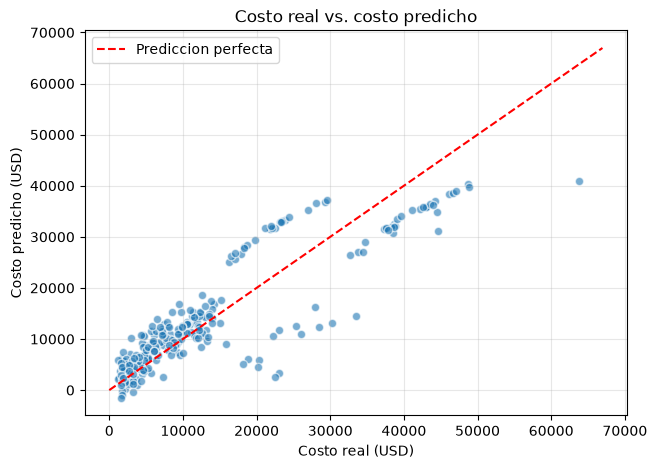

In [ ]:
# Paso 08: costo real (x) vs costo predicho (y) + diagonal perfecta
limite = max(y_test.max(), y_pred.max()) * 1.05

plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred, alpha=0.6, edgecolors="white")
plt.plot([0, limite], [0, limite], "r--", label="Prediccion perfecta")
plt.xlabel("Costo real (USD)")
plt.ylabel("Costo predicho (USD)")
plt.title("Costo real vs. costo predicho")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [ ]:
# Paso 08 extra: comprobar la hipotesis midiendo el error por grupo
error = (y_test - y_pred).abs()

print("MAE fumadores   :", round(error[X_test["smoker_yes"] == 1].mean(), 2), "USD")
print("MAE no fumadores:", round(error[X_test["smoker_yes"] == 0].mean(), 2), "USD")

MAE fumadores   : 8348.08 USD
MAE no fumadores: 3129.74 USD


<div style="background:#059669;color:#fff;padding:8px 16px;border-radius:8px;font-family:'Segoe UI',sans-serif;font-weight:700;font-size:0.95rem;display:inline-block">Respuestas · Paso 08</div>

- **Predice mejor en costos bajos y medios** (hasta ~20 000 USD): los puntos quedan muy pegados a la diagonal. **Predice peor en costos altos** (más de 30 000 USD), donde los puntos se separan.
- **Los puntos alejados están por debajo de la diagonal** → lo predicho es menor que lo real → el modelo **subestima** los costos altos (llega a subestimar más de 20 000 USD).
- **Sí se ven dos grupos:** una nube compacta abajo (casi todos los no fumadores) y una franja dispersa arriba a la izquierda de la diagonal (fumadores).
- **Hipótesis:** los mayores errores los provocan los **fumadores**, sobre todo si además tienen el BMI alto. La celda extra lo confirma: el MAE de los fumadores es de **8 348 USD** frente a **3 130 USD** de los no fumadores (casi 3 veces más).

<div style="background:linear-gradient(120deg,#4F46E5,#7E22CE);color:#fff;padding:14px 20px;border-radius:10px;margin-top:22px;font-family:'Segoe UI',sans-serif">
<div style="font-family:'Consolas',monospace;font-size:0.72rem;opacity:.85;letter-spacing:.12em">PASO 09</div>
<div style="font-size:1.25rem;font-weight:700">Predecir el costo de nuevos solicitantes</div>
</div>

Un modelo entrenado se usa para estimar casos nuevos. Para ello, los datos nuevos deben prepararse **exactamente igual** que los de entrenamiento: mismas columnas, en el mismo orden.

1. Crea un DataFrame con los tres solicitantes de la tabla siguiente.
2. Codifica sus variables con `pd.get_dummies` y alinea las columnas con las de `X` usando `reindex(columns=X.columns, fill_value=0)`.
3. Predice el costo anual de cada solicitante con `modelo.predict`.

| Solicitante | `age` | `sex` | `bmi` | `children` | `smoker` | `region` |
|---|---|---|---|---|---|---|
| **A** | 45 | male | 33.5 | 2 | yes | southeast |
| **B** | 45 | male | 33.5 | 2 | no | southeast |
| **C** | 25 | female | 22.0 | 0 | no | northwest |

<div style="border-left:4px solid #7E22CE;background:#F5F3FF;padding:12px 18px;border-radius:0 8px 8px 0;margin:12px 0;font-family:'Segoe UI',sans-serif">
<div style="color:#7E22CE;font-weight:700;font-size:0.78rem;letter-spacing:.08em;text-transform:uppercase">Para entregar · Paso 09</div>
<div style="margin-top:6px">Las tres predicciones. Responde:</div>
<ul style="margin:6px 0 0 0;padding-left:18px;line-height:1.55">
<li>¿Por qué es necesario el paso de <code>reindex</code>? ¿Qué ocurriría sin él?</li>
<li>Los solicitantes A y B solo difieren en una característica: ¿cuánto cambia la predicción entre ellos y qué coeficiente del Paso 07 explica esa diferencia?</li>
</ul>
</div>

In [ ]:
# Paso 09: preparar los 3 solicitantes EXACTAMENTE igual que el entrenamiento
solicitantes = pd.DataFrame({
    "age":      [45, 45, 25],
    "sex":      ["male", "male", "female"],
    "bmi":      [33.5, 33.5, 22.0],
    "children": [2, 2, 0],
    "smoker":   ["yes", "no", "no"],
    "region":   ["southeast", "southeast", "northwest"],
}, index=["A", "B", "C"])

# 1) codificar el texto a 0/1
nuevos = pd.get_dummies(solicitantes, drop_first=True, dtype=int)

# 2) alinear: mismas columnas y mismo orden que X (las que faltan, en 0)
nuevos = nuevos.reindex(columns=X.columns, fill_value=0)

# 3) predecir
solicitantes["costo_estimado_USD"] = modelo.predict(nuevos)
solicitantes

,age,sex,bmi,children,smoker,region,costo_estimado_USD
A,45,male,33.5,2,yes,southeast,34750.518637
B,45,male,33.5,2,no,southeast,11099.389781
C,25,female,22.0,0,no,northwest,1909.209738


<div style="background:#059669;color:#fff;padding:8px 16px;border-radius:8px;font-family:'Segoe UI',sans-serif;font-weight:700;font-size:0.95rem;display:inline-block">Respuestas · Paso 09</div>

| Solicitante | Costo estimado |
|---|---:|
| **A** (45 años, fumador) | **34 750.52 USD** |
| **B** (45 años, no fumador) | **11 099.39 USD** |
| **C** (25 años, no fumadora) | **1 909.21 USD** |

- **¿Por qué `reindex`?** Porque el modelo espera **exactamente las mismas columnas, en el mismo orden** con las que fue entrenado. `get_dummies` sobre 3 filas puede omitir alguna categoría que no aparece (por ejemplo `region_northeast`) o ponerlas en otro orden. `reindex(columns=X.columns, fill_value=0)` fuerza ese orden y rellena con 0 las que falten. **Sin él**: `predict` daría error de columnas distintas o, peor, asignaría los coeficientes a la columna equivocada y las predicciones serían incorrectas.
- **A y B solo cambian en `smoker`:** la diferencia entre sus predicciones es **23 651.13 USD**, que es exactamente el coeficiente de **`smoker_yes`** del Paso 07.

<div style="background:linear-gradient(120deg,#059669,#0D9488);color:#fff;padding:16px 22px;border-radius:10px;margin-top:26px;font-family:'Segoe UI',sans-serif">
<div style="font-family:'Consolas',monospace;font-size:0.72rem;opacity:.85;letter-spacing:.12em">ANTES DE ENVIAR</div>
<div style="font-size:1.2rem;font-weight:700">Checklist de entrega</div>
</div>

- [ ] El notebook se ejecuta de principio a fin (*Restart & Run All*) sin errores.
- [ ] Cada paso tiene su título y sus respuestas escritas en celdas de texto (interpretadas, no solo números).
- [ ] El archivo `insurance.csv` está en la misma carpeta que el notebook.
- [ ] Subido a tu repositorio de GitHub junto con el archivo de datos.
- [ ] Enlace enviado a la plataforma virtual en el apartado **Práctica 2**.